# RF Proximity Matrix t-SNE

Short report: replace Euclidean distance with a Random Forest proximity distance.
This is better for mixed continuous + one-hot data because similarity is defined by shared RF leaf assignments.

## 1. Imports and Data

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.manifold import TSNE
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    silhouette_score,
    classification_report,
)
from sklearn.metrics import pairwise_distances
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import LabelEncoder

RANDOM_STATE = 42
PROJECT = Path.cwd()
if not (PROJECT / "data").exists():
    PROJECT = PROJECT.parent

OUT_DIR = PROJECT / "visualization" / "outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 130
sns.set_theme(style="whitegrid", context="notebook")

In [2]:
DATA_PATH = PROJECT / "data" / "processed_fullyonehot" / "fullyonehot.csv"
df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip()

target_col = "Target"
feature_cols = [c for c in df.columns if c != target_col]

label_encoder = LabelEncoder()
y_all = label_encoder.fit_transform(df[target_col])

train_idx, holdout_idx = train_test_split(
    np.arange(len(df)),
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y_all,
    shuffle=True,
)
val_idx, test_idx = train_test_split(
    holdout_idx,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_all[holdout_idx],
    shuffle=True,
)

X_all = df[feature_cols].astype("float32")
X_train = X_all.iloc[train_idx]
X_val = X_all.iloc[val_idx]
X_test = X_all.iloc[test_idx]
y_train = y_all[train_idx]
y_val = y_all[val_idx]
y_test = y_all[test_idx]

split_all = np.empty(len(df), dtype=object)
split_all[train_idx] = "train"
split_all[val_idx] = "val"
split_all[test_idx] = "test"

print("Data path:", DATA_PATH)
print("Full one-hot data:", df.shape)
print("Train / Val / Test:", X_train.shape, X_val.shape, X_test.shape)
display(pd.Series(label_encoder.inverse_transform(y_all)).value_counts().to_frame("count"))

Data path: /Users/husrcf/Code/Machine-Learning-Project/data/processed_fullyonehot/fullyonehot.csv
Full one-hot data: (4424, 263)
Train / Val / Test: (3096, 262) (664, 262) (664, 262)


,count
Graduate,2209
Dropout,1421
Enrolled,794


## 2. Train Random Forest

In [3]:
rf = RandomForestClassifier(
    n_estimators=400,
    max_depth=8,
    max_features="sqrt",
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_f1 = cross_val_score(rf, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)

rf.fit(X_train, y_train)
test_pred = rf.predict(X_test)
test_proba = rf.predict_proba(X_test)

metrics = {
    "CV macro-F1 mean": cv_f1.mean(),
    "CV macro-F1 std": cv_f1.std(),
    "Test accuracy": accuracy_score(y_test, test_pred),
    "Test macro-F1": f1_score(y_test, test_pred, average="macro"),
    "Test AUC OVR": roc_auc_score(y_test, test_proba, multi_class="ovr", average="macro"),
}
display(pd.Series(metrics).to_frame("value").round(4))
print(classification_report(y_test, test_pred, target_names=label_encoder.classes_))

,value
CV macro-F1 mean,0.6937
CV macro-F1 std,0.0142
Test accuracy,0.7741
Test macro-F1,0.7355
Test AUC OVR,0.9021


              precision    recall  f1-score   support

     Dropout       0.85      0.70      0.77       214
    Enrolled       0.49      0.69      0.57       119
    Graduate       0.88      0.85      0.87       331

    accuracy                           0.77       664
   macro avg       0.74      0.75      0.74       664
weighted avg       0.80      0.77      0.78       664



## 3. Build RF Proximity Distance

In [4]:
leaves = rf.apply(X_all)
print("Leaf index matrix:", leaves.shape)

# Hamming distance over tree leaf IDs equals 1 - RF proximity.
# If two samples often share leaves, their distance is small.
rf_distance = pairwise_distances(leaves, metric="hamming").astype("float32")
np.fill_diagonal(rf_distance, 0.0)

print("Distance matrix:", rf_distance.shape, rf_distance.dtype)
print("Distance range:", float(rf_distance.min()), float(rf_distance.max()))

Leaf index matrix: (4424, 400)


Distance matrix: (4424, 4424) float32
Distance range: 0.0 1.0


## 4. t-SNE with Precomputed RF Distance

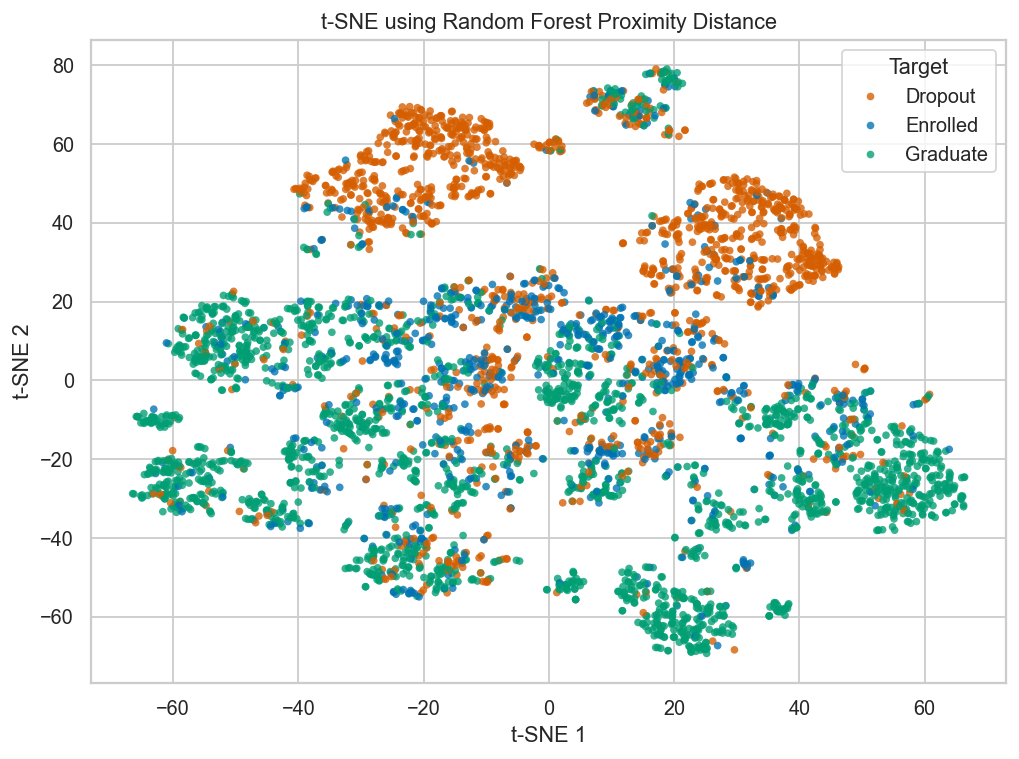

In [5]:
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="random",
    metric="precomputed",
    random_state=RANDOM_STATE,
)
embedding = tsne.fit_transform(rf_distance)

plot_df = pd.DataFrame(embedding, columns=["TSNE1", "TSNE2"])
plot_df["Target"] = label_encoder.inverse_transform(y_all)
plot_df["Split"] = split_all

palette = {"Dropout": "#d55e00", "Enrolled": "#0072b2", "Graduate": "#009e73"}
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(
    data=plot_df,
    x="TSNE1",
    y="TSNE2",
    hue="Target",
    hue_order=["Dropout", "Enrolled", "Graduate"],
    palette=palette,
    s=18,
    alpha=0.78,
    linewidth=0,
    ax=ax,
)
ax.set_title("t-SNE using Random Forest Proximity Distance")
ax.set_xlabel("t-SNE 1")
ax.set_ylabel("t-SNE 2")
ax.legend(title="Target", frameon=True)
plt.tight_layout()
fig.savefig(OUT_DIR / "rf_proximity_tsne.png", bbox_inches="tight")
plt.show()

## 5. Compact Quality Checks

In [6]:
def knn_label_agreement(distance, labels, k=15):
    nn = NearestNeighbors(n_neighbors=k + 1, metric="precomputed")
    nn.fit(distance)
    indices = nn.kneighbors(return_distance=False)[:, 1:]
    return (labels[indices] == labels[:, None]).mean()

quality = {
    "RF-distance silhouette": silhouette_score(rf_distance, y_all, metric="precomputed"),
    "Embedding silhouette": silhouette_score(embedding, y_all),
    "RF-distance KNN label agreement@15": knn_label_agreement(rf_distance, y_all, k=15),
    "Random same-label baseline": pd.Series(y_all).value_counts(normalize=True).pow(2).sum(),
}
display(pd.Series(quality).to_frame("value").round(4))

,value
RF-distance silhouette,0.0285
Embedding silhouette,0.0082
RF-distance KNN label agreement@15,0.6934
Random same-label baseline,0.3847


## 6. RF Feature Importance

,Feature,Importance
12,Curricular units 2nd sem (approved),0.13821
13,Curricular units 2nd sem (grade),0.10737
6,Curricular units 1st sem (approved),0.10100
7,Curricular units 1st sem (grade),0.07866
11,Curricular units 2nd sem (evaluations),0.05070
255,Tuition fees up to date_1,0.05069
254,Tuition fees up to date_0,0.04473
5,Curricular units 1st sem (evaluations),0.03836
2,Age at enrollment,0.03050
259,Scholarship holder_1,0.02278


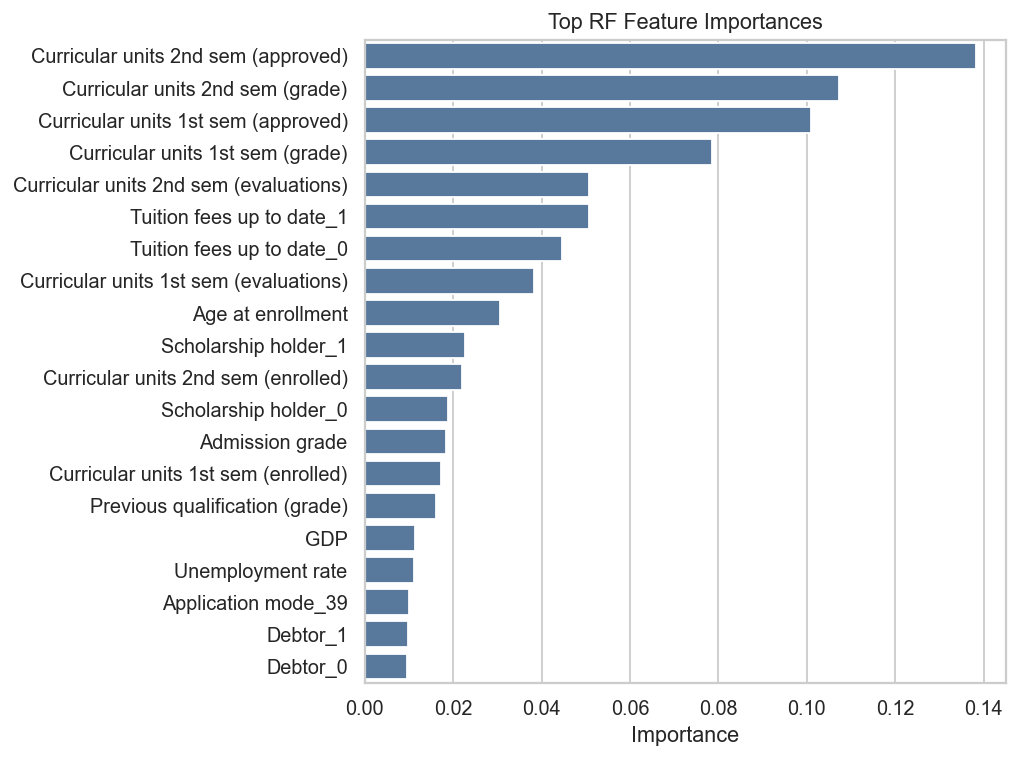

In [7]:
importance_df = (
    pd.DataFrame({"Feature": feature_cols, "Importance": rf.feature_importances_})
    .sort_values("Importance", ascending=False)
    .head(20)
)
display(importance_df.round(5))

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(data=importance_df, y="Feature", x="Importance", color="#4c78a8", ax=ax)
ax.set_title("Top RF Feature Importances")
ax.set_xlabel("Importance")
ax.set_ylabel("")
plt.tight_layout()
fig.savefig(OUT_DIR / "rf_feature_importance_top20.png", bbox_inches="tight")
plt.show()

## 7. Brief Conclusion

RF proximity t-SNE uses supervised tree topology instead of raw Euclidean distance.
If the RF metrics are strong and the t-SNE map forms clearer target neighborhoods, this visualization is more meaningful for mixed one-hot + continuous data than ordinary Euclidean t-SNE.
Still, this is a supervised visualization, so it should be described as model-guided structure rather than unsupervised discovery.